![Python Banner](../../Image/05_03_uplift_learners.png)


# 3.4 Uplift XGBoost Regression


## Overview

A standard predictive model asks: *"What outcome do we expect for this unit?"*

An **uplift model** asks a different question:

> *"How much would the outcome change **because of the treatment** for this unit, given their covariates?"*

That quantity is the **Conditional Average Treatment Effect (CATE)**. For a unit with covariates $X = x$ and a continuous outcome $Y$:

$$\tau(x) = \mathbb{E}[Y \mid T = 1, X = x] - \mathbb{E}[Y \mid T = 0, X = x]$$

where $T = 1$ is treated and $T = 0$ is control. **Heterogeneity** means $\tau(x)$ varies with $x$: some subgroups benefit strongly, others barely, and some may be harmed.

For **binary outcomes** (e.g. conversion yes/no), the CATE is:

$$\tau(x) = P(Y = 1 \mid T = 1, X = x) - P(Y = 1 \mid T = 0, X = x)$$

## Why gradient boosting for uplift?

`UpliftXGBoost` is a **T-learner** with gradient-boosted trees as the base learner:

1. Fit one ensemble on control units ($T = 0$) to estimate $\hat{\mu}_0(x)$.
2. Fit a separate ensemble on treated units ($T = 1$) to estimate $\hat{\mu}_1(x)$.
3. Predict CATE as the difference:

$$\hat{\tau}(x) = \hat{\mu}_1(x) - \hat{\mu}_0(x)$$

| Aspect | Uplift random forest | Uplift XGBoost |
|--------|----------------------|----------------|
| Class | `UpliftRandomForest` | `UpliftXGBoost` |
| Base learner | Bagged uplift trees | Gradient-boosted trees |
| Splitting rule | Squared CATE gap | T-learner only |
| Strengths | Treatment-aware splits; individual trees can be drawn | Flexible nonlinear surfaces |

The model output is $\hat{\tau}(x)$ on the scale of $Y$. Here $Y$ is `lnr`, so a CATE of $-0.12$ is a **0.12 log-point lower** gonorrhea rate for that profile.

#### From ATE to targeted policy

| CATE region | Interpretation | Targeting decision |
|-------------|----------------|-------------------|
| **High positive** $\tau(x)$ | Large expected benefit from treatment | Priority targets |
| **Near zero** | Treatment adds little | Skip / low priority |
| **Negative** $\tau(x)$ | Treatment may worsen outcomes | Actively avoid treating |

The abortion dataset has a single policy indicator (`repeal`), so this notebook stays on the binary path.


## Set Up



In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
    "causaldata", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from pycausalml import (
    CausalTree,
    InteractionTree,
    RLearner,
    SLearner,
    TLearner,
    UpliftRandomForest,
    UpliftXGBoost,
)
from pycausalml.tree_based_models import plot_causal_tree
from pycausalml.uplift_learners import (
    format_uplift_tree,
    plot_uplift_curve,
    plot_uplift_tree,
    qini_coefficient,
    qini_curve,
)

plt.rcParams["figure.dpi"] = 110


def f_filter(X, y, w, names, order=1):
    """Rank features by the partial F statistic of treatment interactions.

    Order 1 tests ``Y ~ X + W + X:W``. Higher orders add powers of ``X`` and
    the matching treatment interactions, following the F-filter idea in
    Zhao et al. (2020).
    """
    y = np.asarray(y, dtype=float)
    w = np.asarray(w, dtype=float)
    rows = []
    for j, name in enumerate(names):
        xj = np.asarray(X[:, j], dtype=float)
        scale = float(np.std(xj))
        if scale < 1e-8:
            rows.append({"feature": name, "score": np.nan})
            continue
        xj = (xj - float(np.mean(xj))) / scale
        main = [np.ones(len(y)), w, xj]
        for power in range(2, order + 1):
            main.append(xj ** power)
        n_main = len(main)
        interactions = [w * (xj ** power) for power in range(1, order + 1)]
        design = np.column_stack(main + interactions)
        try:
            full = sm.OLS(y, design).fit()
            restricted = sm.OLS(y, design[:, :n_main]).fit()
            q = design.shape[1] - n_main
            score = ((restricted.ssr - full.ssr) / q) / (full.ssr / full.df_resid)
        except Exception:
            score = np.nan
        rows.append({"feature": name, "score": float(score)})
    return pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)


def plot_qini_models(y, treatment, scores, title):
    fig, ax = plt.subplots(figsize=(6.8, 4.4))
    table = []
    for name, score in scores.items():
        curve = qini_curve(y, treatment, score)
        ax.plot(curve["fraction"], curve["qini"], label=name)
        table.append({"model": name, "qini": qini_coefficient(y, treatment, score)})
    ax.set_xlabel("Fraction targeted")
    ax.set_ylabel("Cumulative incremental gain")
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    return fig, pd.DataFrame(table)


print("Imported PyCausalML")


Imported PyCausalML


### Data

The abortion dataset is loaded from `causaldata`, the same source as the causal-tree tutorial. It records state-year observations on gonorrhea rates, with a binary indicator for early repeal of abortion prohibition. Risky sexual behavior is proxied by gonorrhea incidence.

**Key variables:**

| Variable | Description |
|----------|-------------|
| `fip` | State FIPS code |
| `age` | Age in years |
| `race` | Race (1 = white, 2 = black) |
| `sex` | Sex (1 = male, 2 = female) |
| `year` | Calendar year |
| `t` | Rescaled time variable |
| `totpop` | Total population (state-level) |
| `ir` | Incarcerated males per 100,000 |
| `crack` | Crack cocaine index |
| `alcohol` | Alcohol consumption per capita |
| `income` | Real income per capita |
| `ur` | State unemployment rate |
| `poverty` | Poverty rate |
| **`repeal`** | **Treatment**: 1 = early repeal of abortion prohibition, 0 = otherwise |
| **`lnr`** | **Outcome**: log gonorrhea rate per 100,000 |
| `pi` | Parental involvement law in effect |
| `bf15` | Indicator: black female aged 15–19 |

Rows with a missing outcome are dropped. A column that is missing for at least 20% of rows (in this file, `fa`) is left out of the covariate matrix. Near-zero-variance columns are dropped, matching the causal-tree tutorial.

> **Causal note:** This is observational panel data. Uplift models estimate conditional contrasts $\hat{\tau}(x)$. A causal reading still needs an identification argument (for example difference-in-differences or fixed effects).


In [3]:
from causaldata import abortion

abortion_df = abortion.load_pandas().data.copy()
print("Abortion dataset loaded. Columns:", list(abortion_df.columns))
print(abortion.NOTE)
print(abortion.DESCRLONG)
print(abortion.SOURCE)


Abortion dataset loaded. Columns: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'repeal', 'acc', 'wht', 'male', 'lnr', 't', 'younger', 'fa', 'pi', 'bf15']
::
    Number of observations - 19584
    Number of variables - 22
    Variables name definitions::
            fip - State FIPS code
            age - Age in years
            race - Race: 1 = white, 2 = black
            year - Year
            t - Year but on a different scale
            sex - Sex: 1 = male, 2 = female
            totpop - Total population
            ir - Incarcerated Males per 100,000
            crack - Crack index
            alcohol - Alcohol consumption per capita
            income - Real income per capita
            ur - State unemployment rate
            poverty - Poverty rate
            repeal - In a state with an early repeal of abortion prohibition
            acc - AIDS mortality per 100,000 cumulative in t, t-1, t-2, t-3
            wht - Whi

### Load and inspect

   fip age  race  year  sex  totpop          ir     crack  alcohol   income  \
0    1  30     2  1985    1   78805  371.475800  0.217438      1.9  11566.0   
1    1  15     1  1985    2  224003   51.389252  0.217438      1.9  11566.0   
2    1  20     2  1985    2   94113  390.875671  0.217438      1.9  11566.0   
3    1  20     1  1985    1  252076  100.836800  0.217438      1.9  11566.0   
4    1  20     2  1985    1   94113  390.875671  0.217438      1.9  11566.0   

   ...  repeal       acc  wht  male       lnr  t  younger   fa  pi  bf15  
0  ...       0  0.679504    0     1  7.880880  1        0  NaN   0     0  
1  ...       0  0.679504    1     0  6.362165  1        1  1.0   0     0  
2  ...       0  0.679504    0     0  8.917793  1        0  NaN   0     0  
3  ...       0  0.679504    1     1  5.906995  1        0  NaN   0     0  
4  ...       0  0.679504    0     1  9.072009  1        0  NaN   0     0  

[5 rows x 22 columns]
repeal
0    17664
1     1920
Name: count, dtype: int

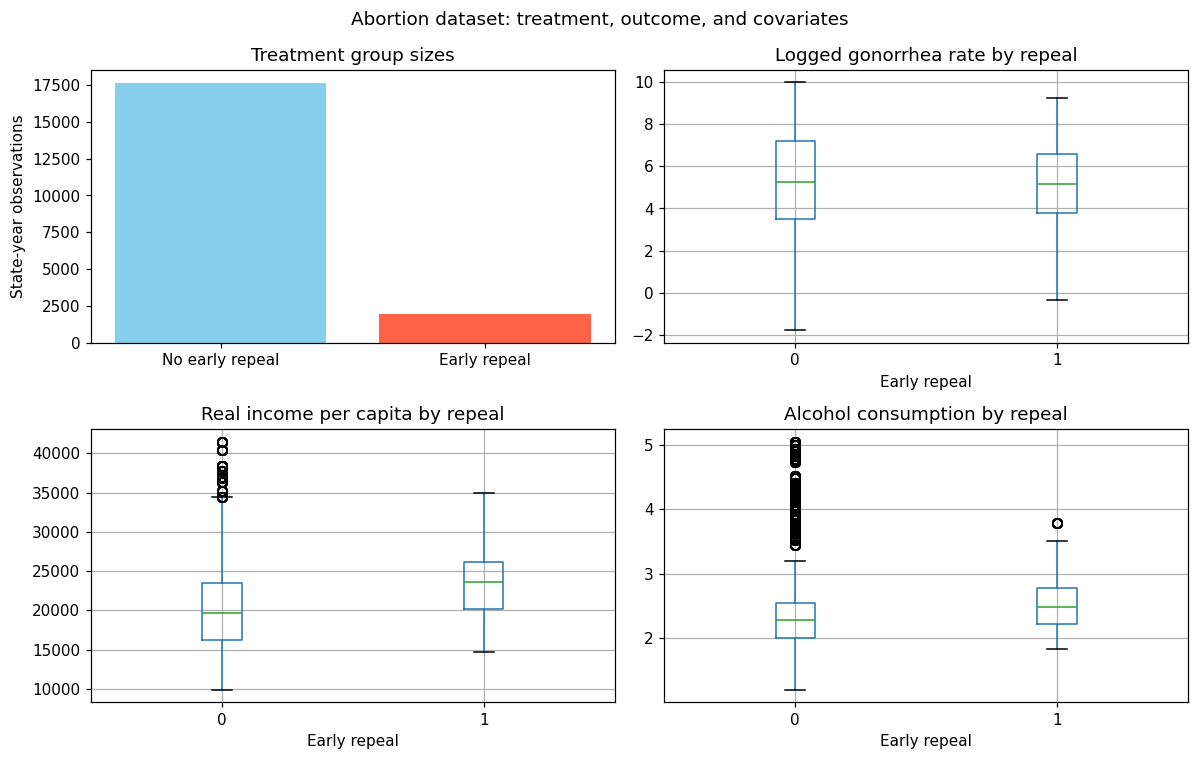

In [4]:
print(abortion_df.head())
print(abortion_df["repeal"].value_counts().sort_index())
print(pd.crosstab(abortion_df["repeal"], abortion_df["race"]))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
counts = abortion_df["repeal"].value_counts().sort_index()
axes[0, 0].bar(["No early repeal", "Early repeal"], counts.to_numpy(), color=["skyblue", "tomato"])
axes[0, 0].set_title("Treatment group sizes")
axes[0, 0].set_ylabel("State-year observations")
abortion_df.boxplot(column="lnr", by="repeal", ax=axes[0, 1])
axes[0, 1].set_title("Logged gonorrhea rate by repeal")
axes[0, 1].set_xlabel("Early repeal")
abortion_df.boxplot(column="income", by="repeal", ax=axes[1, 0])
axes[1, 0].set_title("Real income per capita by repeal")
axes[1, 0].set_xlabel("Early repeal")
abortion_df.boxplot(column="alcohol", by="repeal", ax=axes[1, 1])
axes[1, 1].set_title("Alcohol consumption by repeal")
axes[1, 1].set_xlabel("Early repeal")
fig.suptitle("Abortion dataset: treatment, outcome, and covariates")
fig.tight_layout()
plt.show()


### Data processing

We restrict to the 15–19 age group and drop rows with any missing values, then define covariate matrix $X$, outcome $Y$, and treatment $W$.

In [5]:
missing_rate = abortion_df.isna().mean()
sparse = missing_rate[missing_rate >= 0.2].index.tolist()
print("Dropped sparse columns:", sparse)
model_df = abortion_df.drop(columns=sparse).dropna().reset_index(drop=True)
feature_names = [c for c in model_df.columns if c not in {"lnr", "repeal"}]
X = model_df[feature_names].to_numpy(dtype=float)
Y = model_df["lnr"].to_numpy(dtype=float)
W = model_df["repeal"].to_numpy(dtype=int)
keep = np.var(X, axis=0) > 1e-10
X = X[:, keep]
feature_names = [name for name, flag in zip(feature_names, keep) if flag]
x_names = feature_names
print("Covariates used:", x_names)
print("n =", len(Y), " treated =", int(W.sum()))


Dropped sparse columns: ['fa']
Covariates used: ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']
n = 17921  treated = 1854


### Train / test split

We use an 80 / 20 random split (seed fixed for reproducibility).

In [6]:
rng_abortion = np.random.default_rng(42)
n = len(Y)
train_idx = rng_abortion.choice(n, size=round(0.8 * n), replace=False)
test_idx = np.setdiff1d(np.arange(n), train_idx)
X_train, X_test = X[train_idx], X[test_idx]
Y_train, Y_test = Y[train_idx], Y[test_idx]
W_train, W_test = W[train_idx], W[test_idx]
print("Training rows:", len(Y_train))
print("Test rows:    ", len(Y_test))
print("Columns:      ", x_names)


Training rows: 14337
Test rows:     3584
Columns:       ['fip', 'age', 'race', 'year', 'sex', 'totpop', 'ir', 'crack', 'alcohol', 'income', 'ur', 'poverty', 'acc', 'wht', 'male', 't', 'younger', 'pi', 'bf15']


Outcome by treatment arm:

In [7]:
arm = pd.DataFrame({"lnr": Y, "repeal": W})
summary = arm.groupby("repeal")["lnr"].agg(mean="mean", sd="std", size="size")
summary.loc["All"] = [float(Y.mean()), float(Y.std()), len(Y)]
print(summary.round(4))


          mean      sd     size
repeal                         
0       5.3031  2.1617  16067.0
1       5.1234  1.8227   1854.0
All     5.2845  2.1297  17921.0


### Feature selection (F-filter)

Following Zhao et al. (2020), each covariate is ranked by the partial F statistic of its interaction with treatment in a linear model of `lnr`. Order 1 tests `lnr ~ x + repeal + x:repeal`. Orders 2 and 3 add higher powers of `x`. Ranking uses the training rows only.

The likelihood-ratio and KL filters in the uplift literature are for binary outcomes. `lnr` is continuous, so the F-filter is the matching choice.


In [8]:
print("Training matrix:", X_train.shape)


Training matrix: (14337, 19)


In [9]:
f_imp_1 = f_filter(X_train, Y_train, W_train, x_names, order=1)
f_imp_2 = f_filter(X_train, Y_train, W_train, x_names, order=2)
f_imp_3 = f_filter(X_train, Y_train, W_train, x_names, order=3)
print("*** Order 1 ***")
print(f_imp_1.head(8).round(3).to_string(index=False))
print("*** Order 2 ***")
print(f_imp_2.head(8).round(3).to_string(index=False))
print("*** Order 3 ***")
print(f_imp_3.head(8).round(3).to_string(index=False))


*** Order 1 ***
feature   score
 totpop 347.665
    wht 127.510
   race 127.510
alcohol  61.162
    acc  56.732
poverty  33.773
 income  25.682
      t   6.779
*** Order 2 ***
feature   score
 totpop 249.348
    wht  64.489
   race  64.489
     ir  52.212
alcohol  31.556
poverty  22.873
    acc  19.134
  crack  16.721
*** Order 3 ***
feature   score
 totpop 114.004
    wht  40.778
   race  40.778
     ir  37.056
alcohol  25.219
poverty  17.190
  crack  15.476
    acc  15.135


#### Feature importance plot

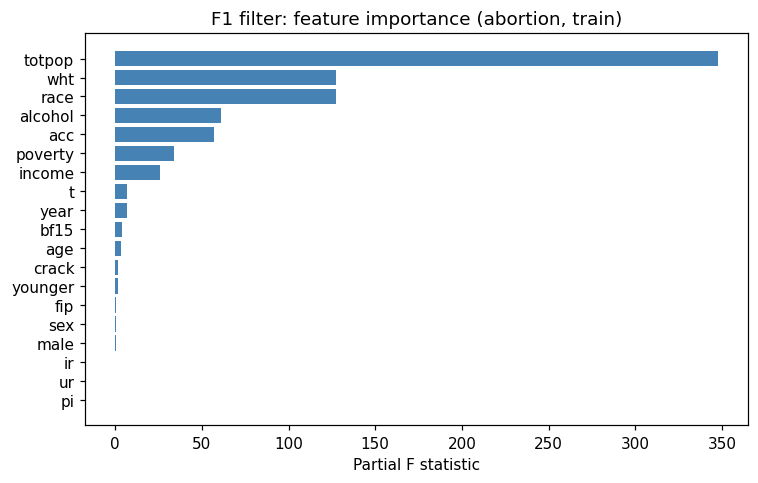

In [10]:
top_bar = f_imp_1.head(min(20, len(f_imp_1))).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top_bar["feature"], top_bar["score"], color="steelblue")
ax.set_xlabel("Partial F statistic")
ax.set_title("F1 filter: feature importance (abortion, train)")
fig.tight_layout()
plt.show()


#### Define feature subsets

In [11]:
ranked_f = f_imp_1["feature"].tolist()
top_3_features = ranked_f[: min(3, len(ranked_f))]
top_6_features = ranked_f[: min(6, len(ranked_f))]
print("Top 3 (F1):", ", ".join(top_3_features))
print("Top 6 (F1):", ", ".join(top_6_features))


Top 3 (F1): totpop, wht, race
Top 6 (F1): totpop, wht, race, alcohol, acc, poverty


### Comparing Learners across Feature Subsets

We compare **cumulative gain** and **AUUC** (area under the uplift curve, normalised) on the test set for T-, R-, and S-learners fitted on all features, the top-6 subset, and the top-3 subset. Here we use **XGBoost** in the T-learner to align with the uplift XGBoost model below.

In [12]:
def fit_learner(Learner, feats, **kwargs):
    cols = [x_names.index(name) for name in feats]
    model = Learner(**kwargs)
    model.fit(X_train[:, cols], W_train, Y_train, feature_names=list(feats))
    return model.predict(X_test[:, cols])

feature_sets = {
    "All": x_names,
    "Top_3": top_3_features,
    "Top_6": top_6_features,
}


### T-Learner (XGBoost)

In [13]:
pred_tl = {
    name: fit_learner(TLearner, feats, learner="xgb", n_estimators=40, random_state=111)
    for name, feats in feature_sets.items()
}
pred_tl["Random"] = np.random.default_rng(42).random(len(Y_test))


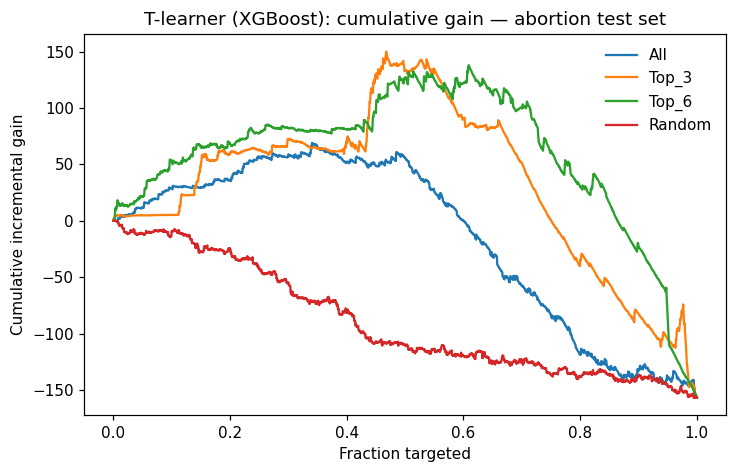

    model      qini
0     All   63.8982
1   Top_3  110.2309
2   Top_6  135.6623
3  Random  -11.4375


In [14]:
fig, auuc_tl = plot_qini_models(
    Y_test, W_test, pred_tl, title="T-learner (XGBoost): cumulative gain — abortion test set"
)
plt.show()
print(auuc_tl.round(4))


### R-learner (random forest)

In [15]:
pred_rl = {
    name: fit_learner(RLearner, feats, learner="rf", n_estimators=15, n_splits=2, random_state=111)
    for name, feats in feature_sets.items()
}
pred_rl["Random"] = np.random.default_rng(42).random(len(Y_test))


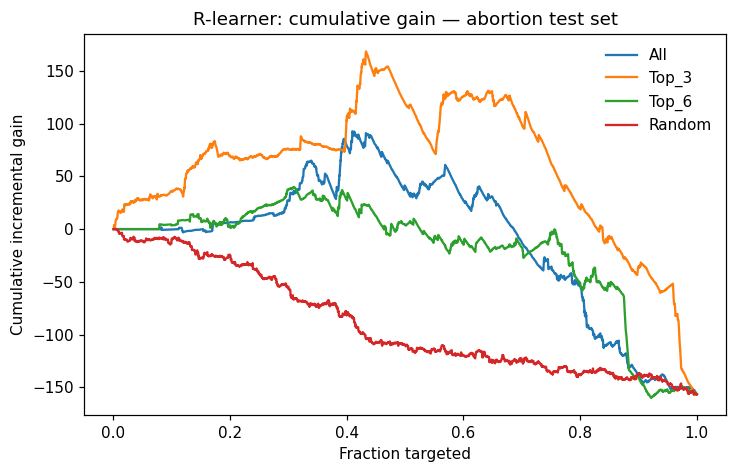

    model      qini
0     All   68.5975
1   Top_3  136.1678
2   Top_6   58.4407
3  Random  -11.4375


In [16]:
fig, auuc_rl = plot_qini_models(
    Y_test, W_test, pred_rl, title="R-learner: cumulative gain — abortion test set"
)
plt.show()
print(auuc_rl.round(4))


### S-Learner (ranger baseline)

In [17]:
pred_sl = {
    name: fit_learner(SLearner, feats, learner="rf", n_estimators=25, random_state=111)
    for name, feats in feature_sets.items()
}
pred_sl["Random"] = np.random.default_rng(42).random(len(Y_test))


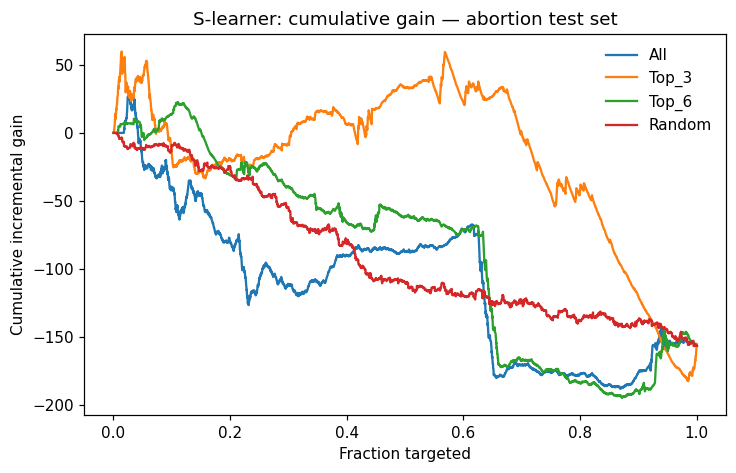

    model     qini
0     All -31.8943
1   Top_3  59.0114
2   Top_6  -7.9036
3  Random -11.4375


In [18]:
fig, auuc_sl = plot_qini_models(
    Y_test, W_test, pred_sl, title="S-learner: cumulative gain — abortion test set"
)
plt.show()
print(auuc_sl.round(4))


### AUUC summary table

In [19]:
auuc_tab = pd.concat([
    auuc_tl.assign(learner="T-learner"),
    auuc_rl.assign(learner="R-learner"),
    auuc_sl.assign(learner="S-learner"),
], ignore_index=True)
print(auuc_tab.round(4).to_string(index=False))


 model     qini   learner
   All  63.8982 T-learner
 Top_3 110.2309 T-learner
 Top_6 135.6623 T-learner
Random -11.4375 T-learner
   All  68.5975 R-learner
 Top_3 136.1678 R-learner
 Top_6  58.4407 R-learner
Random -11.4375 R-learner
   All -31.8943 S-learner
 Top_3  59.0114 S-learner
 Top_6  -7.9036 S-learner
Random -11.4375 S-learner


> **Reading the table:** Higher AUUC means better uplift ranking. Smaller feature sets can match or beat "all features" when the dropped covariates are noisy — this is the practical payoff of filter-based feature selection.

## Uplift XGBoost

`UpliftXGBoost` fits one boosted tree ensemble per treatment arm and returns CATE as the difference of the two predicted means. Treatment-effect split criteria (KL, interaction trees) live on `UpliftTree` and `UpliftRandomForest`.

### Fit the T-learner


In [20]:
uplift_model = UpliftXGBoost(
    n_estimators=80,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    random_state=111,
)
uplift_model.fit(X_train, W_train, Y_train, feature_names=x_names)
pred_tr = uplift_model.predict(X_train)
pred_te = uplift_model.predict(X_test)
print(
    "Mean predicted CATE — train:", round(float(pred_tr.mean()), 4),
    "| test:", round(float(pred_te.mean()), 4),
)


Mean predicted CATE — train: -0.0465 | test: -0.0402


The `full_output = TRUE` argument returns the control arm prediction, treatment arm prediction, and CATE (delta) for each unit — useful for auditing and downstream analysis.

In [21]:
mu0, mu1 = uplift_model.predict_potential_outcomes(X_test)
pred_full = pd.DataFrame({"control": mu0, "treated": mu1, "cate": pred_te})
pred_full.head()


,control,treated,cate
0,5.742962,5.658687,-0.084276
1,5.980757,5.640155,-0.340602
2,5.136722,5.143744,0.007022
3,7.741099,7.289889,-0.451210
4,4.497364,4.813944,0.316580


Model summary:

In [22]:
print(pd.Series(uplift_model.feature_importance(), index=x_names).sort_values(ascending=False).round(4))


race       0.7211
age        0.0638
income     0.0252
sex        0.0246
alcohol    0.0232
year       0.0231
totpop     0.0216
ir         0.0194
acc        0.0165
poverty    0.0165
fip        0.0162
ur         0.0158
crack      0.0129
wht        0.0000
male       0.0000
t          0.0000
younger    0.0000
pi         0.0000
bf15       0.0000
dtype: float64


## Comparing uplift XGBoost and an uplift random forest

Both models return CATE on the outcome scale. XGBoost is a T-learner of boosted trees. The random-forest comparison uses `TLearner(learner="rf")` and `UpliftRandomForest` on the same train/test split.

### T-learner random forest


In [23]:
uplift_rf_tl = TLearner(learner="rf", n_estimators=30, random_state=111)
uplift_rf_tl.fit(X_train, W_train, Y_train, feature_names=x_names)
pred_rf_tl_tr = uplift_rf_tl.predict(X_train)
pred_rf_tl_te = uplift_rf_tl.predict(X_test)
print(
    "Uplift RF (T-learner) — mean CATE train:", round(float(pred_rf_tl_tr.mean()), 4),
    "| test:", round(float(pred_rf_tl_te.mean()), 4),
)


Uplift RF (T-learner) — mean CATE train: -0.1338 | test: -0.1181


In [24]:
pred_rf_tl_full = pd.DataFrame({
    "control": uplift_rf_tl.mu0_.predict(X_test),
    "treated": uplift_rf_tl.mu1_.predict(X_test),
    "cate": pred_rf_tl_te,
})
pred_rf_tl_full.head()


,control,treated,cate
0,5.405854,4.648734,-0.757120
1,5.790270,5.781762,-0.008508
2,5.384153,4.624442,-0.759711
3,8.224475,7.662443,-0.562032
4,3.951916,4.077706,0.125790


### Interaction-tree random forest

The random forest also supports treatment-effect-aware splitting via interaction trees (`evaluation_function = "IT"`), which uplift XGBoost does not provide.

In [25]:
uplift_rf_it = UpliftRandomForest(
    criterion="ed", n_trees=12, max_depth=4, min_samples_leaf=60, random_state=111
)
uplift_rf_it.fit(X_train, W_train, Y_train, feature_names=x_names)
pred_rf_it_te = uplift_rf_it.predict(X_test)
print("Uplift RF — mean CATE (test):", round(float(pred_rf_it_te.mean()), 4))


Uplift RF — mean CATE (test): -0.0726


In [26]:
print("RF T-learner importance:")
print(pd.Series(
    0.5 * (uplift_rf_tl.mu0_.feature_importances_ + uplift_rf_tl.mu1_.feature_importances_),
    index=x_names,
).sort_values(ascending=False).round(4).head(8))
print("Uplift-forest importance:")
print(pd.Series(uplift_rf_it.feature_importance(), index=x_names).sort_values(ascending=False).round(4).head(8))


RF T-learner importance:
wht        0.3782
race       0.3355
age        0.1557
income     0.0286
alcohol    0.0246
sex        0.0180
male       0.0155
year       0.0116
dtype: float64
Uplift-forest importance:
totpop     0.3897
ir         0.1909
fip        0.1742
alcohol    0.0805
poverty    0.0749
acc        0.0185
ur         0.0181
race       0.0161
dtype: float64


### Mean CATE and prediction correlation

In [27]:
cmp_mean = pd.DataFrame({
    "Model": ["Uplift XGBoost", "T-learner random forest", "Uplift random forest"],
    "Mean_CATE_train": [pred_tr.mean(), pred_rf_tl_tr.mean(), np.nan],
    "Mean_CATE_test": [pred_te.mean(), pred_rf_tl_te.mean(), pred_rf_it_te.mean()],
})
print(cmp_mean.round(4).to_string(index=False))
corr_tab = pd.DataFrame({
    "Pair": ["XGBoost vs RF T-learner", "XGBoost vs uplift forest", "RF T-learner vs uplift forest"],
    "Correlation": [
        np.corrcoef(pred_te, pred_rf_tl_te)[0, 1],
        np.corrcoef(pred_te, pred_rf_it_te)[0, 1],
        np.corrcoef(pred_rf_tl_te, pred_rf_it_te)[0, 1],
    ],
})
print(corr_tab.round(4).to_string(index=False))


                  Model  Mean_CATE_train  Mean_CATE_test
         Uplift XGBoost          -0.0465         -0.0402
T-learner random forest          -0.1338         -0.1181
   Uplift random forest              NaN         -0.0726
                         Pair  Correlation
      XGBoost vs RF T-learner       0.7870
     XGBoost vs uplift forest       0.4339
RF T-learner vs uplift forest       0.3169


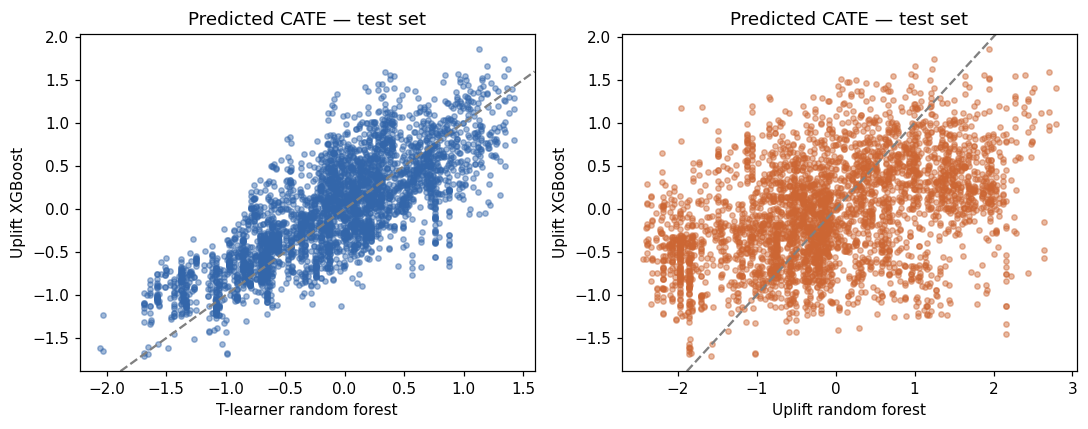

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(pred_rf_tl_te, pred_te, s=12, alpha=0.45, c="#3366AA")
axes[0].axline((0, 0), slope=1, color="gray", ls="--")
axes[0].set_xlabel("T-learner random forest")
axes[0].set_ylabel("Uplift XGBoost")
axes[0].set_title("Predicted CATE — test set")
axes[1].scatter(pred_rf_it_te, pred_te, s=12, alpha=0.45, c="#CC6633")
axes[1].axline((0, 0), slope=1, color="gray", ls="--")
axes[1].set_xlabel("Uplift random forest")
axes[1].set_ylabel("Uplift XGBoost")
axes[1].set_title("Predicted CATE — test set")
fig.tight_layout()
plt.show()


## Evaluation

### Gain curve and AUUC on the test set

The **cumulative gain curve** plots, as we move through units in descending order of predicted CATE, how much *actual* treatment benefit we capture relative to random assignment. A curve bowing above the diagonal indicates useful uplift ranking.

In [29]:
df_gain = pd.DataFrame({
    "is_treated": W_test,
    "outcome": Y_test,
    "uplift_xgb": pred_te,
    "uplift_rf_tl": pred_rf_tl_te,
    "uplift_rf_it": pred_rf_it_te,
    "Random": np.random.default_rng(42).random(len(X_test)),
})
df_gain.head()


,is_treated,outcome,uplift_xgb,uplift_rf_tl,uplift_rf_it,Random
0,0,6.362165,-0.084276,-0.757120,1.230609,0.773956
1,0,6.135781,-0.340602,-0.008508,-1.936277,0.438878
2,0,5.544787,0.007022,-0.759711,1.319814,0.858598
3,0,8.268040,-0.451210,-0.562032,-1.132073,0.697368
4,0,4.560173,0.316580,0.125790,1.267901,0.094177


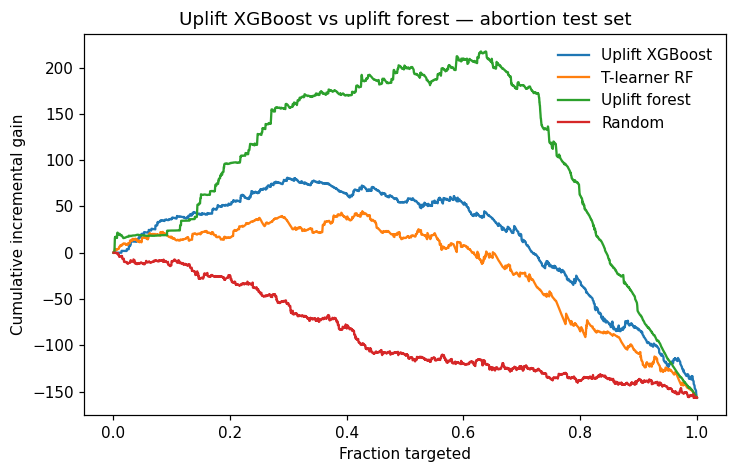

         model     qini
Uplift XGBoost  94.3411
  T-learner RF  63.9860
 Uplift forest 174.8450
        Random -11.4375


In [30]:
scores = {
    "Uplift XGBoost": df_gain["uplift_xgb"],
    "T-learner RF": df_gain["uplift_rf_tl"],
    "Uplift forest": df_gain["uplift_rf_it"],
    "Random": df_gain["Random"],
}
fig, auuc_uplift = plot_qini_models(
    Y_test, W_test, scores, title="Uplift XGBoost vs uplift forest — abortion test set"
)
plt.show()
print(auuc_uplift.round(4).to_string(index=False))


> **Reading AUUC:** higher is better uplift ranking. T-learner XGBoost and T-learner RF both estimate $\hat{\mu}_1(x) - \hat{\mu}_0(x)$ with different base learners; the IT forest optimises treatment–covariate interaction splits and may rank units differently even when mean CATE is similar.

#### Distribution of predicted CATE

Fitting on the **full dataset** compares how each model spreads heterogeneity across all observed covariate profiles.

In [31]:
ux_full = UpliftXGBoost(n_estimators=40, max_depth=3, learning_rate=0.05, random_state=111)
ux_full.fit(X, W, Y, feature_names=x_names)
uf_tl_full = TLearner(learner="rf", n_estimators=20, random_state=111)
uf_tl_full.fit(X, W, Y, feature_names=x_names)
uf_it_full = UpliftRandomForest(
    criterion="ed", n_trees=8, max_depth=3, min_samples_leaf=80, random_state=111
)
uf_it_full.fit(X, W, Y, feature_names=x_names)
pred_cate_xgb = ux_full.predict(X)
pred_cate_rf_tl = uf_tl_full.predict(X)
pred_cate_rf_it = uf_it_full.predict(X)


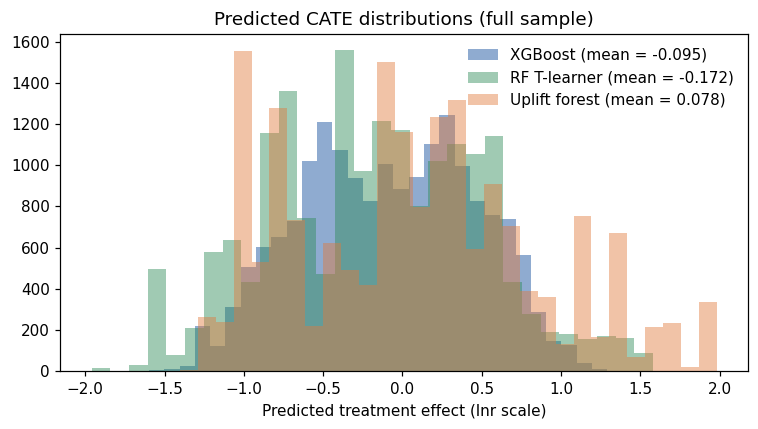

In [32]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(pred_cate_xgb, bins=30, color="#3366AA", alpha=0.55, label=f"XGBoost (mean = {pred_cate_xgb.mean():.3f})")
ax.hist(pred_cate_rf_tl, bins=30, color="#2E8B57", alpha=0.45, label=f"RF T-learner (mean = {pred_cate_rf_tl.mean():.3f})")
ax.hist(pred_cate_rf_it, bins=30, color="#E07A3D", alpha=0.45, label=f"Uplift forest (mean = {pred_cate_rf_it.mean():.3f})")
ax.set_xlabel("Predicted treatment effect (lnr scale)")
ax.set_title("Predicted CATE distributions (full sample)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### Variable importance: XGBoost vs random forest (T-learner arms)

For **fair comparison of drivers**, we extract importance from the T-learner arm models and average across control / treated fits.

In [33]:
imp_xgb = pd.Series(uplift_model.feature_importance(), index=x_names).sort_values(ascending=False)
print(imp_xgb.head(8).round(4))


race       0.7211
age        0.0638
income     0.0252
sex        0.0246
alcohol    0.0232
year       0.0231
totpop     0.0216
ir         0.0194
dtype: float64


In [34]:
imp_rf = pd.Series(
    0.5 * (uplift_rf_tl.mu0_.feature_importances_ + uplift_rf_tl.mu1_.feature_importances_),
    index=x_names,
).sort_values(ascending=False)
print(imp_rf.head(8).round(4))


wht        0.3782
race       0.3355
age        0.1557
income     0.0286
alcohol    0.0246
sex        0.0180
male       0.0155
year       0.0116
dtype: float64


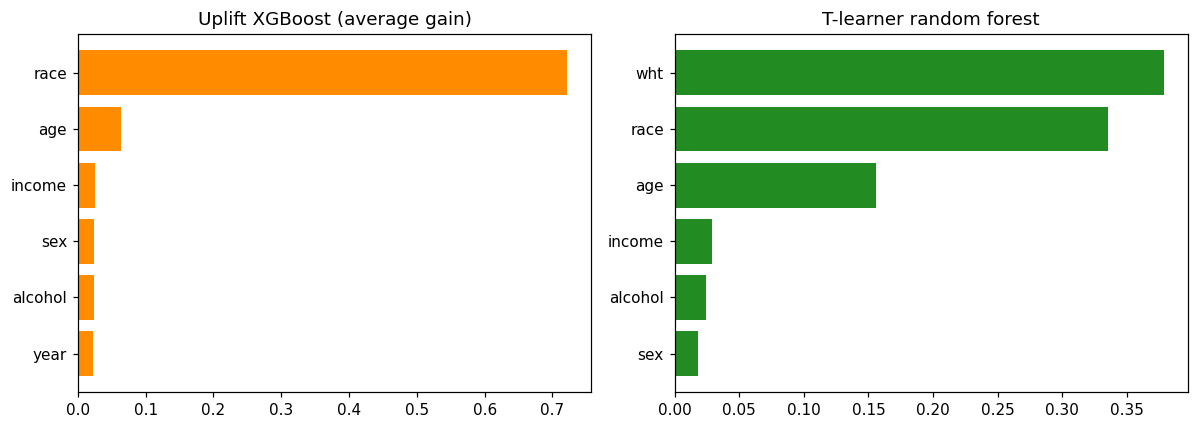

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
left = imp_xgb.head(6).iloc[::-1]
right = imp_rf.head(6).iloc[::-1]
axes[0].barh(left.index, left.to_numpy(), color="darkorange")
axes[0].set_title("Uplift XGBoost (average gain)")
axes[1].barh(right.index, right.to_numpy(), color="forestgreen")
axes[1].set_title("T-learner random forest")
fig.tight_layout()
plt.show()


## Interpretable Single-Tree Models

Boosted ensembles are powerful but opaque. A single **interaction tree** or **causal inference tree** summarises learned heterogeneity in human-readable split rules, useful for communicating findings to non-technical stakeholders.

### Interaction tree (IT)

In [36]:
it_fit = InteractionTree(max_depth=3, min_samples_leaf=80, random_state=111)
it_fit.fit(X_train, W_train, Y_train, feature_names=x_names)
print(format_uplift_tree(it_fit))


[alcohol <= 2.150]  gain=3348.7738  tau=-0.119  n=14337
  [poverty <= 13.700]  gain=865.0966  tau=-0.965  n=5045
    [wht <= 0.000]  gain=500.3254  tau=-0.367  n=2574
      * leaf  tau=-0.836  n=1268
      * leaf  tau=0.046  n=1306
    [ir <= 139.480]  gain=465.2184  tau=-1.195  n=2471
      * leaf  tau=-1.442  n=866
      * leaf  tau=-0.533  n=1605
  [totpop <= 36115.000]  gain=3088.1481  tau=0.047  n=9292
    [fip <= 33.000]  gain=2099.1684  tau=-0.947  n=3253
      * leaf  tau=-1.354  n=2185
      * leaf  tau=0.357  n=1068
    [alcohol <= 2.720]  gain=1450.1082  tau=0.262  n=6039
      * leaf  tau=-0.076  n=4871
      * leaf  tau=1.165  n=1168


Leaf labels show $\hat{\tau} \approx \mathbb{E}[Y \mid T=1] - \mathbb{E}[Y \mid T=0]$ within each region.

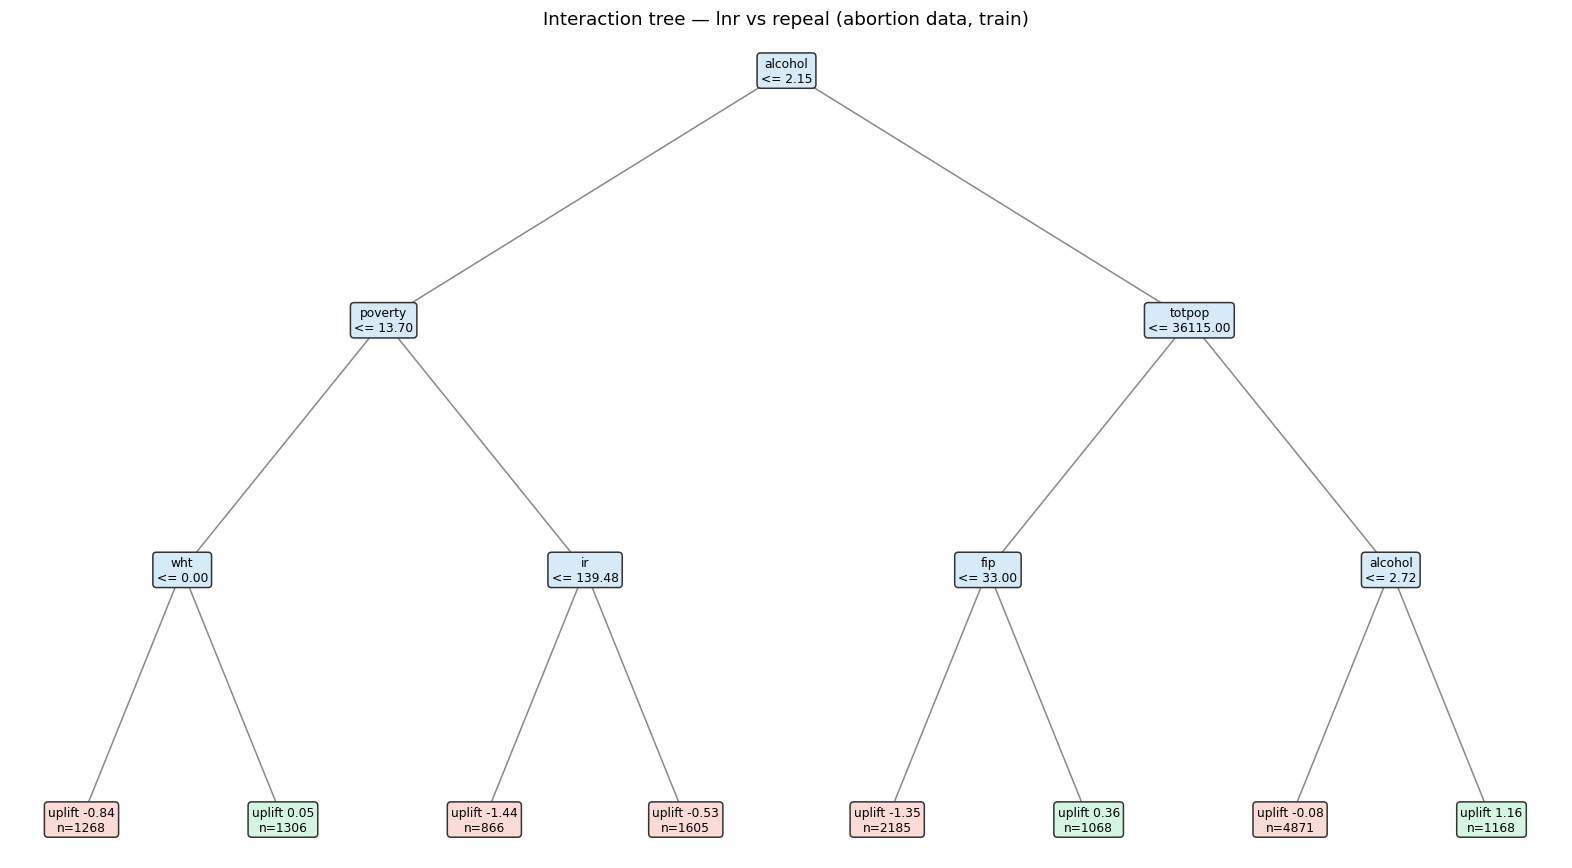

In [37]:
plot_uplift_tree(it_fit, title="Interaction tree — lnr vs repeal (abortion data, train)")
plt.show()


### Causal inference tree (CIT)

    cate     n                                         conditions
0  1.406   797                     acc <= 5.919 AND race <= 1.000
1 -0.649   172  acc <= 5.919 AND race > 1.000 AND year <= 1985...
2 -0.571   402  acc <= 5.919 AND race > 1.000 AND year > 1985.000
3 -1.108  1904  acc > 5.919 AND totpop <= 132551.040 AND fip <...
4  0.916  1366  acc > 5.919 AND totpop <= 132551.040 AND fip >...
5  1.878  1398  acc > 5.919 AND totpop > 132551.040 AND totpop...
6 -0.207  1129  acc > 5.919 AND totpop > 132551.040 AND totpop...


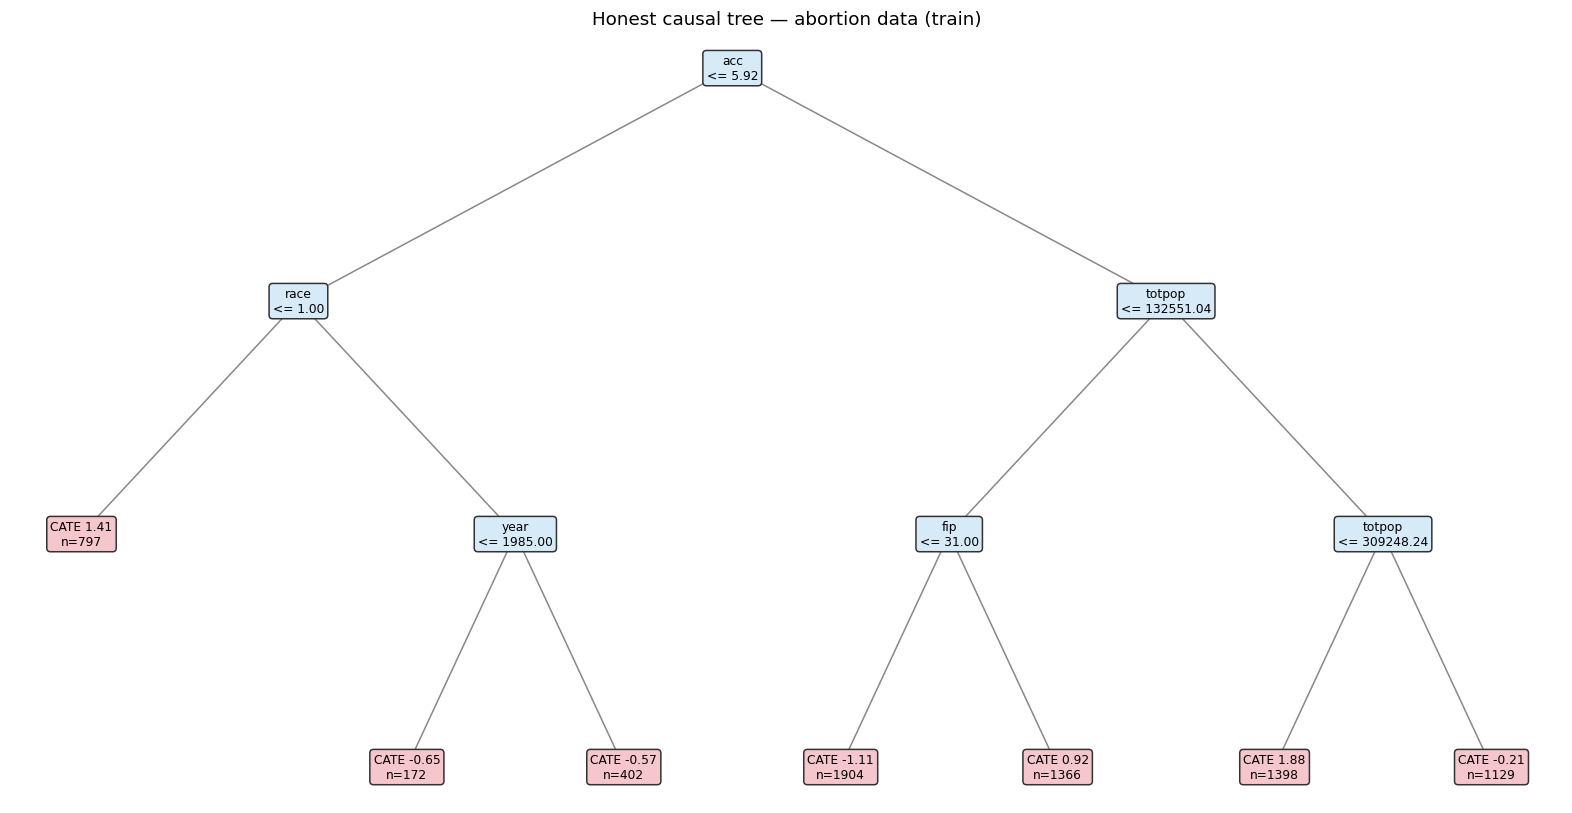

In [38]:
cit_fit = CausalTree(max_depth=3, min_samples_leaf=80, honest=True, random_state=111)
cit_fit.fit(X_train, W_train, Y_train, feature_names=x_names)
print(pd.DataFrame(cit_fit.rules()).round(3))
plot_causal_tree(cit_fit, title="Honest causal tree — abortion data (train)")
plt.show()


## Explaining predicted CATE

`explain` decomposes predicted CATE into covariate contributions. A positive value means that feature pushes the predicted treatment effect up. The explanation is about $\hat{\tau}(X)$, not the raw outcome.


In [39]:
sv = uplift_model.explain(X_train, max_samples=24, n_permutations=4, random_state=2026)
print("SHAP array shape:", sv.values.shape)


SHAP array shape: (24, 19)


### Global feature importance

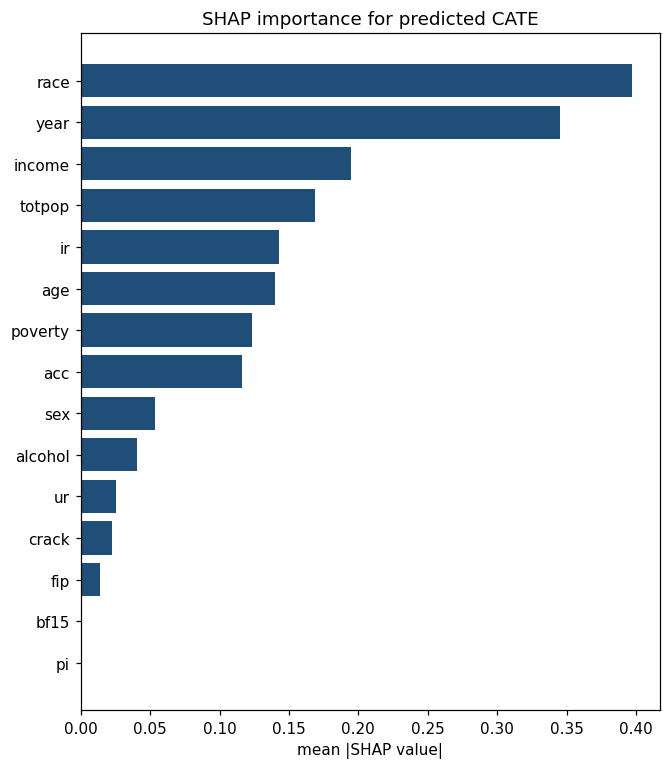

In [40]:
sv.plot_importance(title="SHAP importance for predicted CATE")
plt.show()


### Dependence plots

These show how a feature's SHAP value changes as the feature value changes — revealing the shape of the heterogeneity.

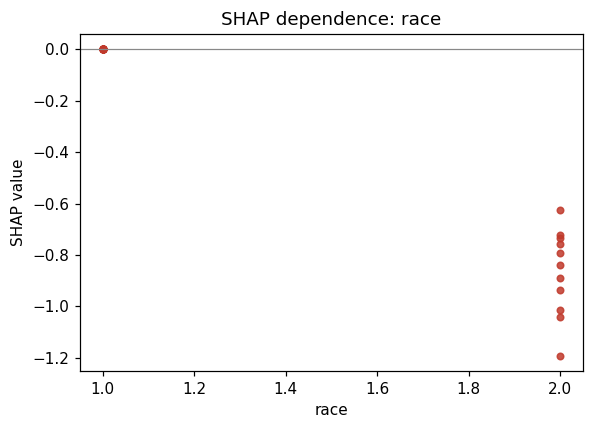

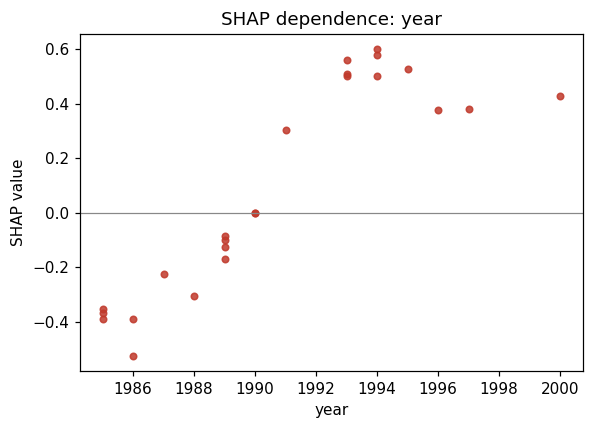

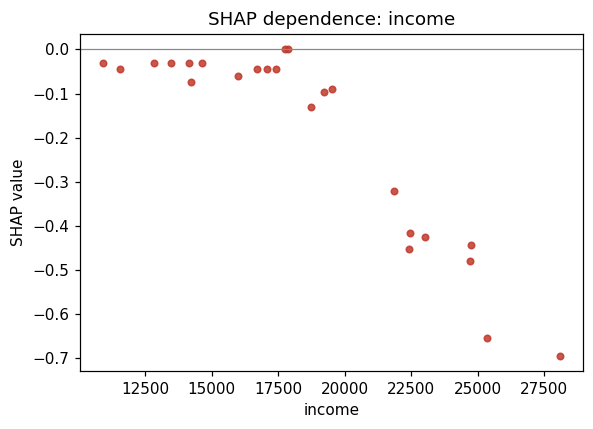

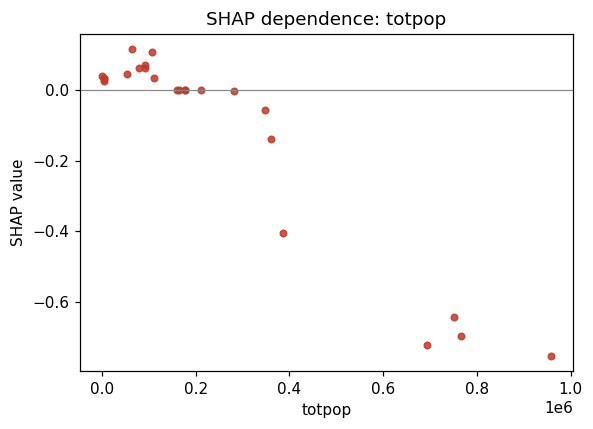

In [41]:
order = np.argsort(sv.importance())[::-1][:4]
for feature in np.asarray(x_names)[order]:
    sv.plot_dependence(feature)
    plt.show()


Interaction between the top two features:

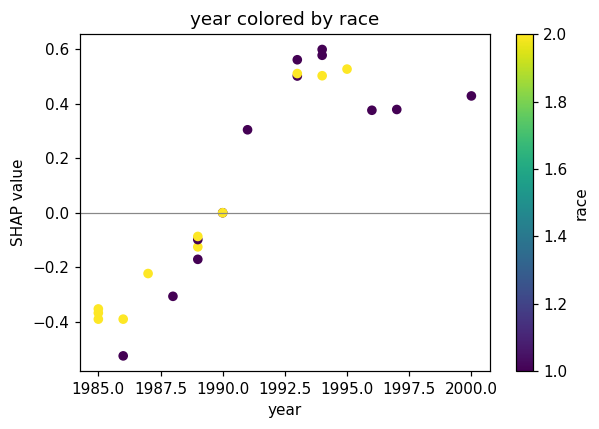

In [42]:
if len(order) >= 2:
    j, k = int(order[1]), int(order[0])
    fig, ax = plt.subplots(figsize=(5.6, 4))
    points = ax.scatter(sv.data[:, j], sv.values[:, j], c=sv.data[:, k], cmap="viridis", s=28)
    fig.colorbar(points, ax=ax, label=x_names[k])
    ax.axhline(0, color="#888888", lw=0.8)
    ax.set_xlabel(x_names[j])
    ax.set_ylabel("SHAP value")
    ax.set_title(f"{x_names[j]} colored by {x_names[k]}")
    fig.tight_layout()
    plt.show()


### Waterfall plot: highest-uplift unit

A waterfall plot decomposes one unit's predicted CATE into covariate contributions, starting from the baseline (mean prediction across background) and adding or subtracting each feature's SHAP value.

Highest predicted CATE in the explain set: 0.5407


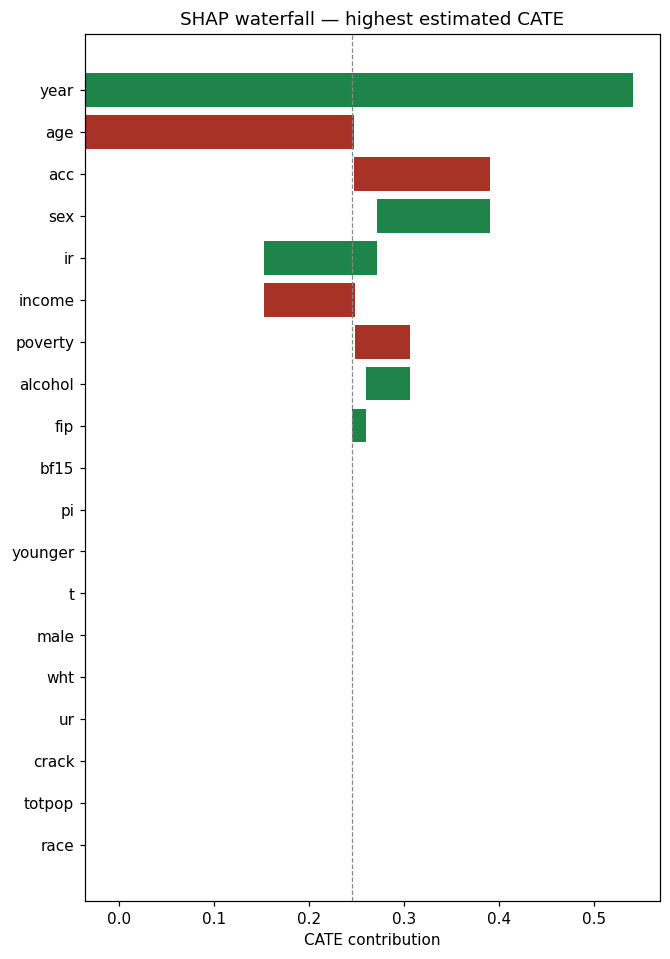

In [43]:
row_id = int(np.argmax(sv.predictions))
print("Highest predicted CATE in the explain set:", round(float(sv.predictions[row_id]), 4))
sv.plot_waterfall(row_id, title="SHAP waterfall — highest estimated CATE")
plt.show()


### SHAP on the test set

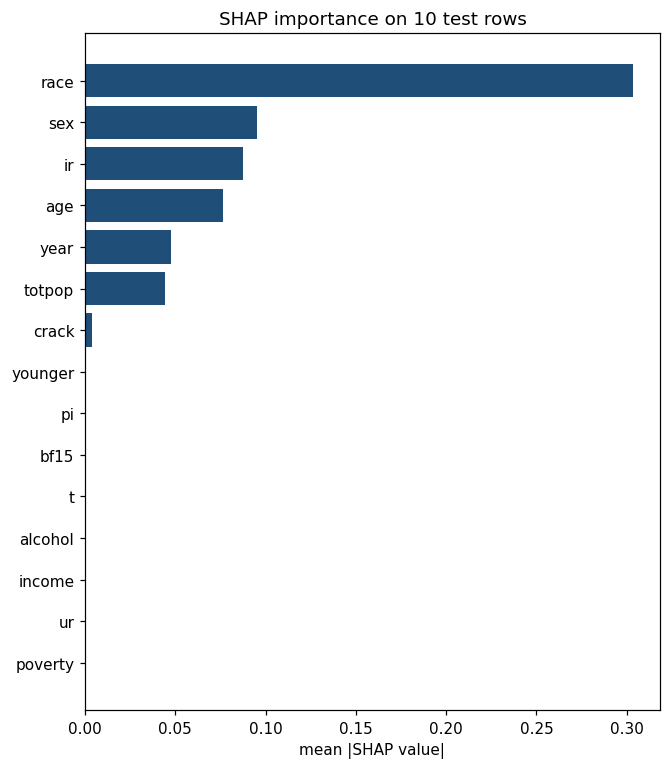

In [44]:
sv_test = uplift_model.explain(X_test[:10], max_samples=10, n_permutations=4, random_state=2026)
sv_test.plot_importance(title="SHAP importance on 10 test rows")
plt.show()


## Summary

This tutorial fits uplift XGBoost on the abortion dataset with PyCausalML and compares it with a T-learner random forest and an uplift forest.

| Step | What we did |
|------|-------------|
| **Data** | Loaded `abortion` from `causaldata`, as in the causal-tree tutorial |
| **Feature selection** | F-filter on the training rows |
| **Learner comparison** | T-learner XGBoost, plus R- and S-learners, scored by the Qini coefficient |
| **Uplift XGBoost** | `UpliftXGBoost` T-learner |
| **Uplift forest** | `TLearner(learner="rf")` and `UpliftRandomForest` on the same split |
| **Single trees** | `InteractionTree` and honest `CausalTree` |
| **SHAP** | `explain` on the XGBoost CATE |

### Key reminders

- Predictions are on the `lnr` scale.
- The sample is observational. Conditional contrasts are not, by themselves, causal effects.
- `UpliftXGBoost` is a T-learner. Use `UpliftRandomForest` when the splits themselves should target treatment-effect heterogeneity.


## Resources

- [Uplift Trees Example — Python CausalML docs](https://causalml.readthedocs.io/en/latest/examples/uplift_trees_with_synthetic_data.html)
- [Feature Selection for Uplift Modelling — Python CausalML docs](https://causalml.readthedocs.io/en/latest/examples/feature_selection.html)
- Zhao, Z., Feng, T., Garg, V., & Cakmak, M. (2020). [Feature Selection Methods for Uplift Modeling](https://arxiv.org/abs/2005.03447). *arXiv*.
- Gutierrez, P., & Gérardy, J.-Y. (2017). [Causal inference and uplift modelling: A review of the literature](http://proceedings.mlr.press/v67/gutierrez17a/gutierrez17a.pdf). *PMLR*.
- Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD*.